
# Task 4: Predicting Insurance Claim Amounts

## Internship: DevelopersHub Corporation

### Objective
The objective of this project is to predict medical insurance charges using personal information such as age, BMI, smoking status, and other relevant features.

### Dataset
Medical Cost Personal Dataset (`insurance.csv`).

### Methodology
1. Dataset exploration and cleaning
2. Exploratory Data Analysis (EDA)
3. Data preprocessing
4. Linear Regression model training
5. Model evaluation using MAE and RMSE
6. Visualization and conclusion


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

df = pd.read_csv("insurance.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:

print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values in categorical columns:")
for col in ["sex", "smoker", "region"]:
    print(f"{col}: {df[col].unique()}")


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Statistical summary:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1

Unique values in categorical columns:
sex: <StringArray>
['female', 'male']
Length: 2, dtype: str
smoker: <StringArray>
['yes', 'no']
Length: 2, dtype: str
region: <StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [4]:

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing numeric values with the median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the mode
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Shape after cleaning:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())


Shape after cleaning: (1337, 7)
Total missing values: 0
Total duplicate rows: 0


C:\Users\Malik\AppData\Local\Temp\ipykernel_12904\2069823503.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


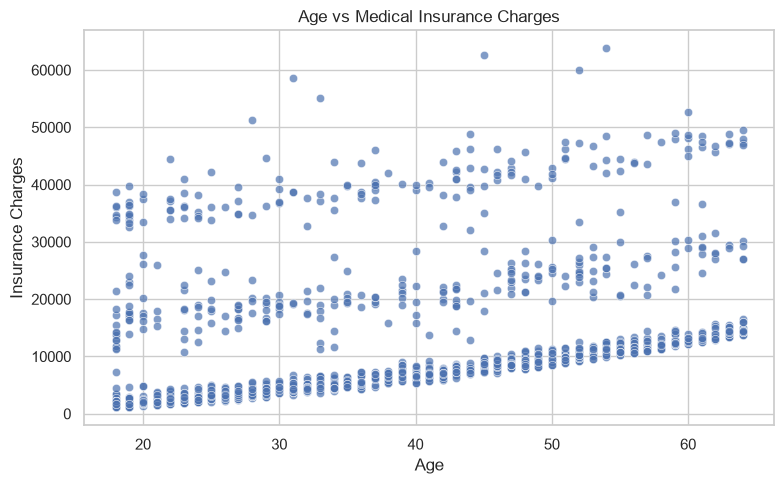

In [5]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    alpha=0.7
)

plt.title("Age vs Medical Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.tight_layout()
plt.show()


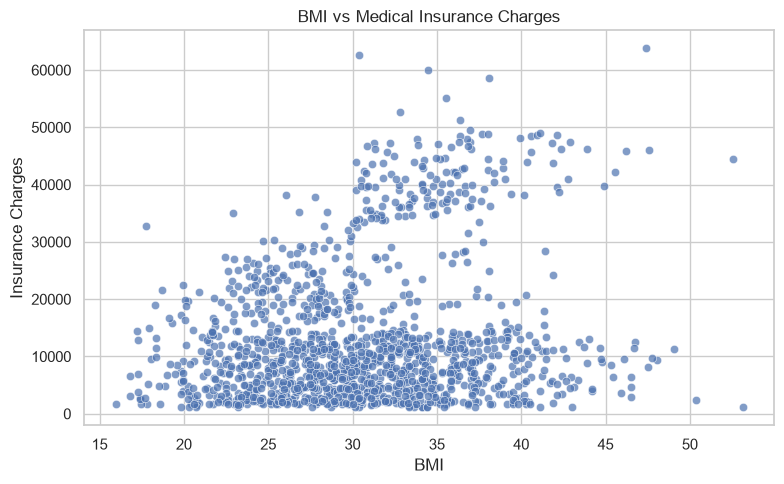

In [6]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    alpha=0.7
)

plt.title("BMI vs Medical Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.tight_layout()
plt.show()


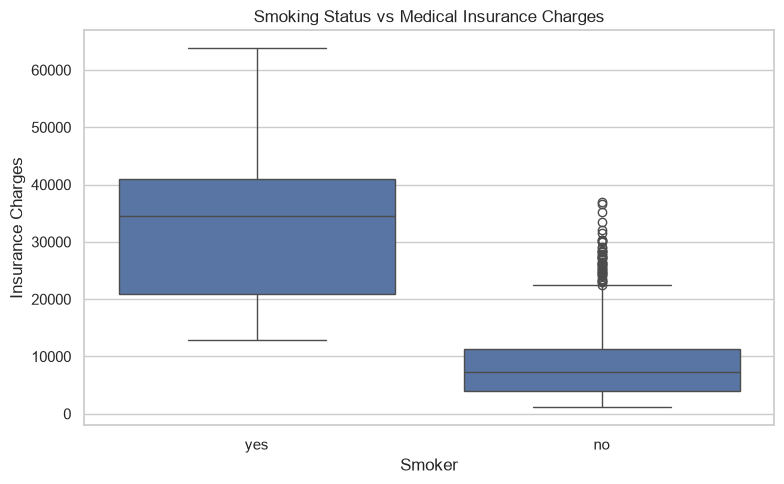

In [7]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="charges"
)

plt.title("Smoking Status vs Medical Insurance Charges")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")
plt.tight_layout()
plt.show()


In [8]:

df_encoded = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

print("Encoded dataset:")
display(df_encoded.head())

print("\nNew columns:")
print(df_encoded.columns.tolist())


Encoded dataset:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0



New columns:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [9]:

X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (1337, 8)
Target shape: (1337,)


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 1069
Testing rows: 268


In [11]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [12]:

y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Charges": y_test.values,
    "Predicted Charges": y_pred
})

print("Actual vs Predicted Insurance Charges:")
display(comparison.head(10))


Actual vs Predicted Insurance Charges:


,Actual Charges,Predicted Charges
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657
5,9304.70190,13149.722353
6,38511.62830,30446.760679
7,2150.46900,1453.288813
8,7345.72660,10633.018402
9,10264.44210,11318.943794


In [13]:

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")


Mean Absolute Error (MAE): 4177.05
Root Mean Squared Error (RMSE): 5956.34
R-squared (R²): 0.8069


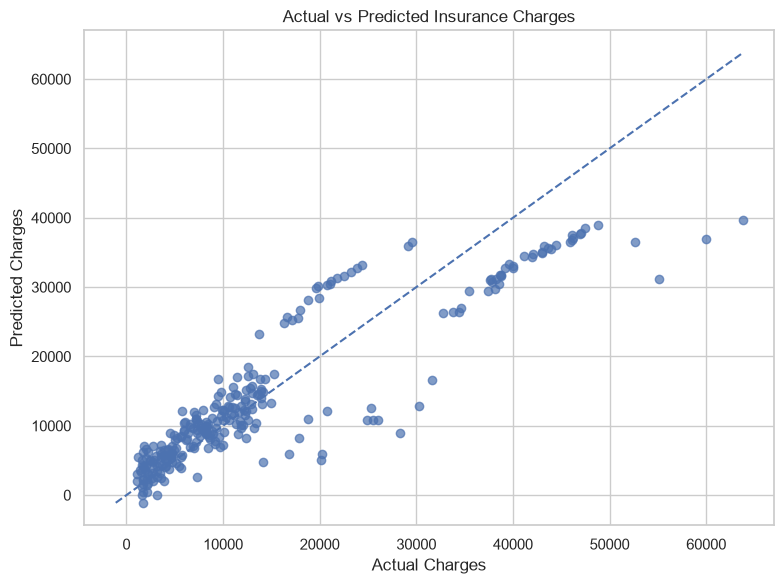

In [14]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.title("Actual vs Predicted Insurance Charges")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.tight_layout()
plt.show()


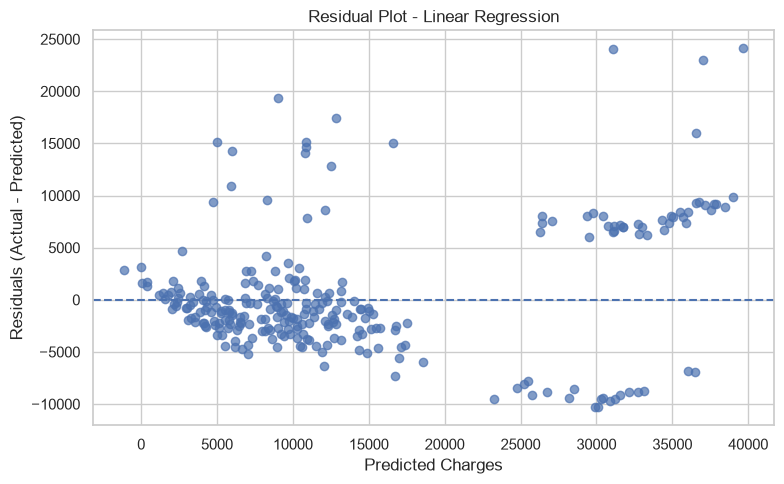

In [15]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals (Actual - Predicted)")
plt.tight_layout()
plt.show()


In [16]:

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(coefficients)


,Feature,Coefficient,Absolute Coefficient
4,smoker_yes,23077.764593,23077.764593
6,region_southeast,-838.919616,838.919616
7,region_southwest,-659.139752,659.139752
2,children,533.009989,533.009989
5,region_northwest,-391.761455,391.761455
1,bmi,318.701441,318.701441
0,age,248.210720,248.210720
3,sex_male,-101.542054,101.542054


# Conclusion

In this project, I developed a Linear Regression model to predict medical insurance charges using the Medical Cost Personal Dataset.

The dataset was explored and cleaned, duplicate records were removed, missing values were handled, and categorical features were encoded. Exploratory Data Analysis was performed to investigate the relationships between age, BMI, smoking status, and insurance charges.

The Linear Regression model was trained using an 80/20 train-test split and evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

The model achieved an MAE of **[insert actual MAE]**, an RMSE of **[insert actual RMSE]**, and an R² score of **[insert actual R²]** on the test dataset.

The visualizations and model evaluation provide insights into insurance charge patterns and prediction errors. The model's estimates may be useful for exploratory analysis, but further validation would be needed before using them for real-world insurance decisions.